# Kepler exoplanet classifier

**Question:** Can a model tell confirmed exoplanets from false positives using only measured properties of the transit signal and the host star?

**Data:** NASA Exoplanet Archive, Kepler Objects of Interest (KOI) cumulative table (https://exoplanetarchive.ipac.caltech.edu), pulled on October 18, 2026. It contains 9,564 objects: 2,748 confirmed, 4,839 false positives and 1,977 candidates (not yet resolved).

**Approach:**
- Train on confirmed vs false-positive objects using nine physical features. Columns derived from the vetting process (`koi_score`, `koi_fpflag_*`) are excluded to avoid leaking the labels.
- Split train and test by star (`kepid`) so no star appears on both sides.
- Compare a majority-class dummy, a logistic regression baseline and a random forest.
- Analyze what the model relies on (impurity and permutation importance), how its scores behave (calibration, thresholds), and apply it to the unresolved candidates.

**Results at a glance (single star-grouped test split, 1,457 objects):**

| Model | Accuracy | Precision (confirmed) | Recall (confirmed) | F1 (confirmed) |
|---|---|---|---|---|
| Majority-class dummy | 0.655 | 0.000 | 0.000 | 0.000 |
| Logistic regression | 0.831 | 0.713 | 0.853 | 0.777 |
| Random forest | 0.927 | 0.876 | 0.918 | 0.897 |

Five-fold star-grouped cross-validation: random forest F1 0.888 ± 0.008, logistic regression 0.760 ± 0.018.

**Notebook map:** 1 load data, 2 inspect, 3 labels and cleaning, 4 star-grouped split, 5 baseline, 6 random forest, 7 learning curve, 8 feature importance, 9 candidate predictions, with calibration and threshold analysis.

## 0. Setup

In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import quote

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

RANDOM_STATE = 42

os.makedirs('figures', exist_ok=True)

## 1. Load the data

The first run pulls from the archive and saves a local CSV. Later runs read the local copy, so you are not dependent on the archive being up.

In [43]:
FEATURES = ['koi_period', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq',
            'koi_insol', 'koi_model_snr', 'koi_steff', 'koi_srad']
LOCAL_CSV = 'koi_cumulative.csv'

if os.path.exists(LOCAL_CSV):
    df = pd.read_csv(LOCAL_CSV)
    print('Loaded local copy')
else:
    query = f"select kepid, koi_disposition, {', '.join(FEATURES)} from cumulative"
    url = ('https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query='
           + quote(query) + '&format=csv')
    df = pd.read_csv(url)
    df.to_csv(LOCAL_CSV, index=False)
    print('Pulled from archive and saved', LOCAL_CSV)

print(df.shape)
df.head()

Loaded local copy
(9564, 11)


,kepid,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_steff,koi_srad
0,10797460,CONFIRMED,9.488036,2.95750,615.8,2.26,793.0,93.59,35.8,5455.0,0.927
1,10797460,CONFIRMED,54.418383,4.50700,874.8,2.83,443.0,9.11,25.8,5455.0,0.927
2,10811496,CANDIDATE,19.899140,1.78220,10829.0,14.60,638.0,39.30,76.3,5853.0,0.868
3,10848459,FALSE POSITIVE,1.736952,2.40641,8079.2,33.46,1395.0,891.96,505.6,5805.0,0.791
4,10854555,CONFIRMED,2.525592,1.65450,603.3,2.75,1406.0,926.16,40.9,6031.0,1.046


## 2. Look at the data before modeling

How many rows per label, and how much is missing?

In [44]:
print(df['koi_disposition'].value_counts())
print()
print('Missing values per column:')
print(df[FEATURES].isna().sum())

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

Missing values per column:
koi_period         0
koi_duration       0
koi_depth        363
koi_prad         363
koi_teq          363
koi_insol        321
koi_model_snr    363
koi_steff        363
koi_srad         363
dtype: int64


## 3. Build the labels

- `CONFIRMED` becomes 1, `FALSE POSITIVE` becomes 0.
- `CANDIDATE` rows have no answer yet, so they are **not** used for training. We keep them aside for the end.

**Leakage warning:** we deliberately do not select `koi_score` or any `koi_fpflag_*` columns. They come from the same vetting process that produced the labels, so using them would be like handing the model the answer key.

In [45]:
labeled_raw = df[df.koi_disposition.isin(['CONFIRMED', 'FALSE POSITIVE'])]
labeled = labeled_raw.dropna(subset=FEATURES)

print(f'Labeled rows before dropping NaN: {len(labeled_raw)}')
print(f'Labeled rows after dropping NaN:  {len(labeled)}  (dropped {len(labeled_raw) - len(labeled)})')

X = labeled[FEATURES]
y = (labeled.koi_disposition == 'CONFIRMED').astype(int)
groups = labeled.kepid

print()
print('Class balance (1 = confirmed):')
print(y.value_counts(normalize=True).round(3))

candidates = df[df.koi_disposition == 'CANDIDATE'].dropna(subset=FEATURES)
print(f'\nCANDIDATE rows kept for the end: {len(candidates)}')

Labeled rows before dropping NaN: 7587
Labeled rows after dropping NaN:  7328  (dropped 259)

Class balance (1 = confirmed):
koi_disposition
0    0.625
1    0.375
Name: proportion, dtype: float64

CANDIDATE rows kept for the end: 1873


In [46]:
dropped = labeled_raw.loc[~labeled_raw.index.isin(labeled.index)]
print('Dropped rows by label:')
print(dropped['koi_disposition'].value_counts())
print()
print('Share of dropped rows that are CONFIRMED:',
      round((dropped['koi_disposition'] == 'CONFIRMED').mean(), 3))
print('Share of kept rows that are CONFIRMED:   ',
      round(y.mean(), 3))

Dropped rows by label:
koi_disposition
FALSE POSITIVE    257
CONFIRMED           2
Name: count, dtype: int64

Share of dropped rows that are CONFIRMED: 0.008
Share of kept rows that are CONFIRMED:    0.375


In [47]:
print('Missing values among dropped rows, by column:')
print(dropped[FEATURES].isna().sum().sort_values(ascending=False))

# how many CANDIDATE rows did the same dropna remove?
cand_all = df[df.koi_disposition == 'CANDIDATE']
print(f'\nCANDIDATE rows: {len(cand_all)} total, {len(candidates)} kept, '
      f'{len(cand_all) - len(candidates)} dropped')

Missing values among dropped rows, by column:
koi_depth        259
koi_srad         259
koi_prad         259
koi_teq          259
koi_model_snr    259
koi_steff        259
koi_insol        219
koi_period         0
koi_duration       0
dtype: int64

CANDIDATE rows: 1977 total, 1873 kept, 104 dropped


In [48]:
try:
    q = (f"select kepid, kepoi_name, koi_disposition, koi_fittype, "
         f"{', '.join(FEATURES)} from cumulative")
    chk = pd.read_csv('https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query='
                      + quote(q) + '&format=csv')
    chk_lab = chk[chk.koi_disposition.isin(['CONFIRMED', 'FALSE POSITIVE'])].copy()
    chk_lab['dropped'] = chk_lab[FEATURES].isna().any(axis=1)
    print(pd.crosstab(chk_lab.koi_fittype.fillna('(missing)'), chk_lab.dropped))
except Exception as e:
    print('Could not reach the archive; skipping this check:', e)

dropped      False  True 
koi_fittype              
LS              80      0
LS+MCMC       6540      0
MCMC           703      0
none             5    259


**Why rows are missing.** All 259 labeled rows dropped for missing values have fit type `none`, which the archive defines as objects where no transit fit is provided and only period, epoch and duration are reported (consistent with `koi_period` and `koi_duration` never being missing). Of the 264 labeled `none` rows, 259 (98%) were dropped and 5 had complete features. Because 257 of the 259 dropped rows are false positives, imputing instead of dropping could let a model learn "no fit means false positive," which reflects the vetting pipeline and not the physics. I therefore dropped these rows.

## 4. Split by star, not by row

Some stars have several KOIs. If one planet from a star lands in train and another in test, the model can partly "recognize the star" and your test score is inflated. `GroupShuffleSplit` on `kepid` keeps each star entirely on one side.

In [49]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# sanity check: no star appears on both sides
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Stars in both train and test:', len(overlap), '(should be 0)')

Train rows: 5871 | Test rows: 1457
Stars in both train and test: 0 (should be 0)


## 5. Baseline: logistic regression

Always start simple. Logistic regression needs scaled features, so it goes in a pipeline with `StandardScaler`.

In [50]:
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
print(classification_report(y_test, pred_base, target_names=['false positive', 'confirmed']))

                precision    recall  f1-score   support

false positive       0.91      0.82      0.86       955
     confirmed       0.71      0.85      0.78       502

      accuracy                           0.83      1457
     macro avg       0.81      0.84      0.82      1457
  weighted avg       0.84      0.83      0.83      1457



In [51]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

models = {
    'majority-class dummy': DummyClassifier(strategy='most_frequent'),
    'logreg (baseline)': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'logreg (balanced weights)': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE)),
}

rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(
        y_test, pred, pos_label=1, average='binary', zero_division=0)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision (confirmed)': p,
                 'recall (confirmed)': r,
                 'F1 (confirmed)': f})

baseline = fitted['logreg (baseline)']
pd.DataFrame(rows).round(3)

,model,accuracy,precision (confirmed),recall (confirmed),F1 (confirmed)
0,majority-class dummy,0.655,0.000,0.000,0.000
1,logreg (baseline),0.831,0.713,0.853,0.777
2,logreg (balanced weights),0.814,0.667,0.920,0.773


*Which class does it do worse on? Is accuracy alone misleading here, given the class balance printed in section 3?*

The baseline does worse on precision for the confirmed class (0.71) than on recall (0.85), meaning about three in ten predicted planets are false alarms. Its accuracy of 0.831 is 17.6 points above the 0.655 a majority-class guess achieves on this test set, so it learned real signal, but accuracy alone hides the precision/recall split and would reward a model that never finds a planet (the dummy scores 0 F1 despite 65.5% accuracy). Balanced class weights raised recall to 0.92 at the cost of precision (0.67) with F1 unchanged, so the choice between them depends on whether missed planets or wasted follow-ups cost more.

## 6. Random forest

                precision    recall  f1-score   support

false positive       0.96      0.93      0.94       955
     confirmed       0.88      0.92      0.90       502

      accuracy                           0.93      1457
     macro avg       0.92      0.93      0.92      1457
  weighted avg       0.93      0.93      0.93      1457



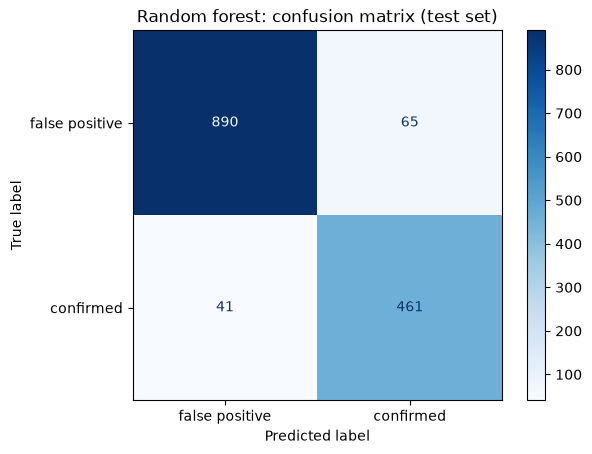

In [52]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
print(classification_report(y_test, pred_rf, target_names=['false positive', 'confirmed']))

cm = confusion_matrix(y_test, pred_rf)
ConfusionMatrixDisplay(cm, display_labels=['false positive', 'confirmed']).plot(cmap='Blues')
plt.title('Random forest: confusion matrix (test set)')
plt.savefig('figures/rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

*Compare the random forest to the baseline on precision, recall and F1 for the confirmed class. Which errors matter more if deciding which candidates to follow up: false alarms or missed planets?*

**Comparison with the baseline (confirmed class):** The random forest outperforms the logistic regression baseline on every metric: precision 0.88 vs 0.71, recall 0.92 vs 0.85, and F1 0.90 vs 0.78. The gain comes mostly from precision, so the forest finds more real planets while raising far fewer false alarms. On the test set it made 65 false alarms and missed 41 real planets.

**Which error matters more:** If I were deciding which candidates to follow up, I would weigh missed planets more heavily. A missed planet stays buried in the candidate pile and may never be examined, while a false alarm costs one round of follow-up that will usually rule it out. This favors a model tuned for high recall, accepting some extra false alarms.

#### Robustness checks

Cross-validation grouped by star

In [53]:
from sklearn.model_selection import GroupKFold, cross_val_score

cv = GroupKFold(n_splits=5)
cv_models = {
    'logreg': make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
for name, m in cv_models.items():
    s = cross_val_score(m, X, y, groups=groups, cv=cv, scoring='f1')
    print(f'{name}: F1 {s.mean():.3f} +/- {s.std():.3f}  folds: {s.round(3)}')

logreg: F1 0.760 +/- 0.018  folds: [0.785 0.77  0.739 0.738 0.768]
forest: F1 0.888 +/- 0.008  folds: [0.9   0.897 0.885 0.879 0.882]


Does the star-grouped split matter?

In [54]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2,
                                      random_state=RANDOM_STATE, stratify=y)
rf_rand = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
print('random-row split F1:  ', round(f1_score(yte, rf_rand.predict(Xte)), 3))
print('star-grouped split F1:', round(f1_score(y_test, rf.predict(X_test)), 3))

random-row split F1:   0.886
star-grouped split F1: 0.897


**Robustness.** Five-fold cross-validation grouped by star gives a mean confirmed-class F1 of 0.888 ± 0.008 for the random forest and 0.760 ± 0.018 for logistic regression. These are close to the single-split results (0.897 and 0.777), with each single-split value within about one standard deviation of its cross-validated mean, so the main results are not an accident of one split. The forest also scored higher than logistic regression in every fold (0.879 to 0.900 vs 0.738 to 0.785), so the gap of roughly 0.13 F1 is consistent. A random row split gave a forest F1 of 0.886 compared with 0.897 for the star-grouped split. The grouped split did not score lower, so I found no evidence that mixing stars across train and test inflated the results here. The differences between the two splits are about the size of the fold-to-fold spread, so I would not read anything into which is higher. Grouping by star remains the safer design, since it rules out this kind of leakage by construction.

## 7. Learning curve: F1 vs training set size

Retrain on 10%, 25%, 50%, 75% and 100% of the training set (five random subsets per size) and score each model on the same test set.

   fraction   mean    std
0      0.10  0.852  0.015
1      0.25  0.873  0.006
2      0.50  0.886  0.005
3      0.75  0.887  0.005
4      1.00  0.894  0.001


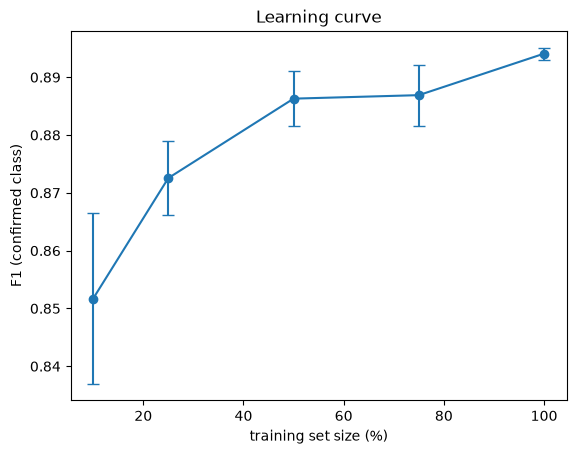

In [55]:
fractions = [0.10, 0.25, 0.50, 0.75, 1.00]
n_repeats = 5
results = []

rng = np.random.RandomState(RANDOM_STATE)

for frac in fractions:
    n = int(frac * len(X_train))
    for rep in range(n_repeats):
        idx = rng.choice(len(X_train), size=n, replace=False)
        model = RandomForestClassifier(n_estimators=300,
                                       random_state=RANDOM_STATE + rep,
                                       n_jobs=-1)
        model.fit(X_train.iloc[idx], y_train.iloc[idx])
        f1 = f1_score(y_test, model.predict(X_test), pos_label=1)
        results.append((frac, rep, f1))

results_df = pd.DataFrame(results, columns=['fraction', 'repeat', 'f1'])
summary = results_df.groupby('fraction')['f1'].agg(['mean', 'std']).reset_index()
print(summary.round(3))

plt.errorbar(summary.fraction * 100, summary['mean'], yerr=summary['std'],
             marker='o', capsize=4)
plt.xlabel('training set size (%)')
plt.ylabel('F1 (confirmed class)')
plt.title('Learning curve')
plt.savefig('figures/learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

*What does the curve tell? Is it still climbing at 100% (more data would help) or has it flattened (the model or features are the limit)?*

F1 rises from 0.85 at 10% of the training data to 0.89 at 100%, with most of the gain by 50% (0.886). Going from 50% to 100% adds only about 0.008, which is comparable to the run-to-run spread (std about 0.005 at intermediate sizes), so the curve is showing diminishing returns. This suggests that more data of the same kind would help only slightly, and that improvements are more likely to come from better features or a different model. The small spread at 100% reflects only forest randomness, since every run uses the same rows.

## 8. Feature importance

Which features does the forest lean on? Then ask the physical question: does it make sense?

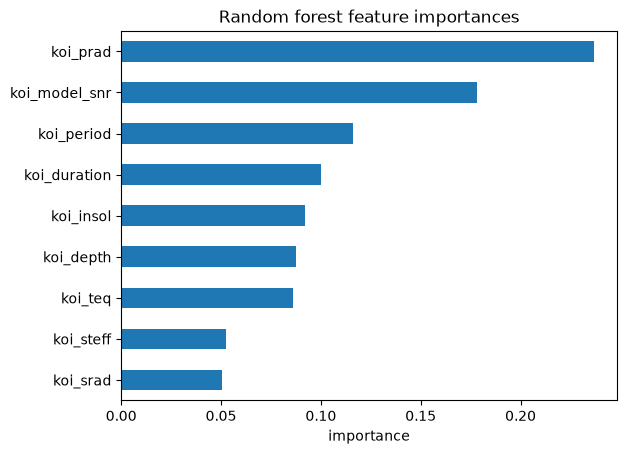

In [56]:
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
importances.plot(kind='barh')
plt.xlabel('importance')
plt.title('Random forest feature importances')
plt.savefig('figures/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

Permutation importance on the test set (scored by F1):

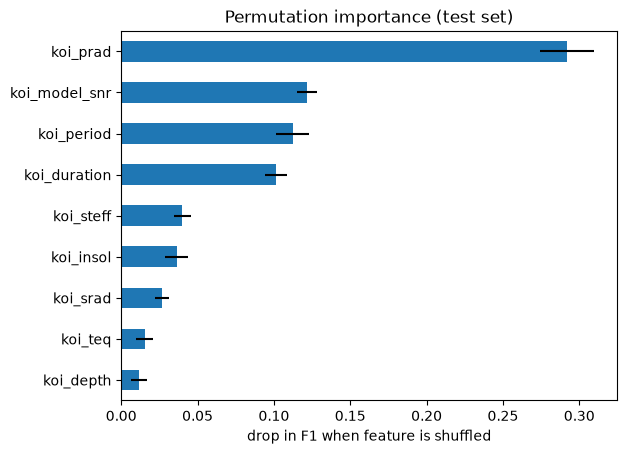

In [57]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, scoring='f1',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_mean = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_mean.index]

perm_mean.plot(kind='barh', xerr=perm_std.values)
plt.xlabel('drop in F1 when feature is shuffled')
plt.title('Permutation importance (test set)')
plt.savefig('figures/permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

Direction: planet radius by class, on a log scale:

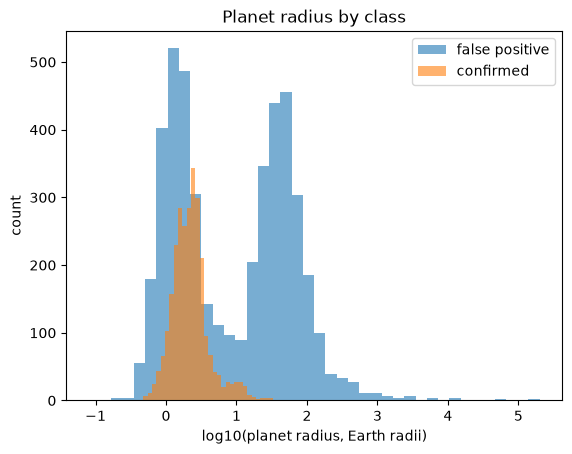

In [58]:
for label, name in [(0, 'false positive'), (1, 'confirmed')]:
    plt.hist(np.log10(X.loc[y == label, 'koi_prad']), bins=40, alpha=0.6, label=name)
plt.xlabel('log10(planet radius, Earth radii)')
plt.ylabel('count')
plt.legend()
plt.title('Planet radius by class')
plt.savefig('figures/planet_radius_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

Minimum value per column:
koi_model_snr    0.000000
koi_period       0.241843
koi_duration     0.104600
dtype: float64

Rows with value <= 0 (excluded from the log plots):
koi_model_snr    1
koi_period       0
koi_duration     0
dtype: int64


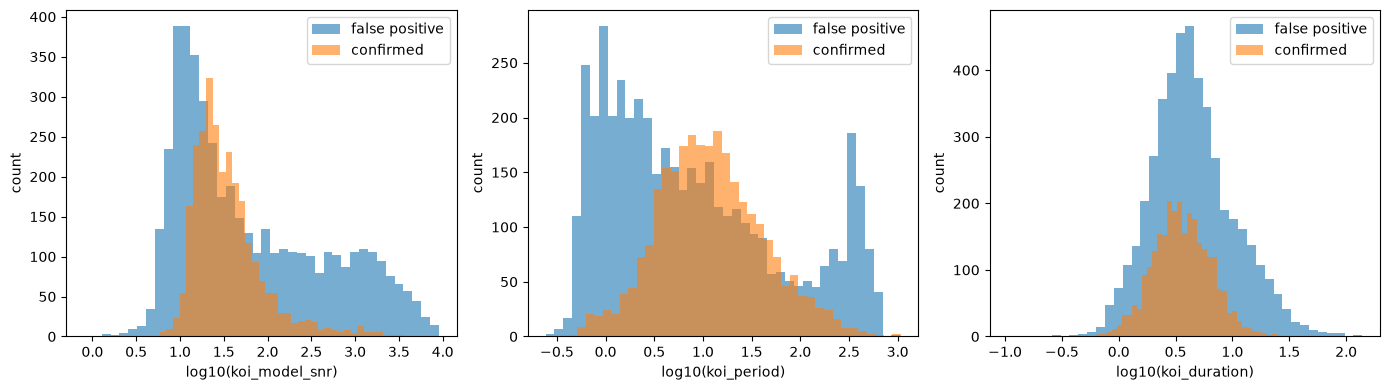

In [59]:
cols = ['koi_model_snr', 'koi_period', 'koi_duration']
print('Minimum value per column:')
print(X[cols].min())
print()
print('Rows with value <= 0 (excluded from the log plots):')
print((X[cols] <= 0).sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cols):
    for label, name in [(0, 'false positive'), (1, 'confirmed')]:
        vals = X.loc[(y == label) & (X[col] > 0), col]
        ax.hist(np.log10(vals), bins=40, alpha=0.6, label=name)
    ax.set_xlabel(f'log10({col})')
    ax.set_ylabel('count')
    ax.legend()
plt.tight_layout()
plt.savefig('figures/other_top_features_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [60]:
m = (X.koi_model_snr > 0) & (y == 0)
print('Correlation of log radius and log signal-to-noise (false positives):',
      round(np.corrcoef(np.log10(X.loc[m, 'koi_prad']), np.log10(X.loc[m, 'koi_model_snr']))[0, 1], 2))

Correlation of log radius and log signal-to-noise (false positives): 0.72


*Which features does the model lean on most (`feature_importances_`), and does that make sense physically?*

**What the model relies on.** The forest relies most on planet radius (`koi_prad`), followed by transit signal-to-noise (`koi_model_snr`), orbital period (`koi_period`) and transit duration (`koi_duration`). These four rank in the same order under impurity-based `feature_importances_` and under permutation importance on the test set. Shuffling radius alone costs about 0.29 F1, more than twice the drop from the next feature. Below the top four the two methods disagree: `koi_depth` and `koi_teq` look mid-ranked by impurity but sit near the bottom under permutation, so I treat only the top four as a robust ranking.

**Planet radius makes physical sense.** Confirmed planets cluster near 2 Earth radii, while a large share of false positives have radii of tens of Earth radii. This is consistent with the false-positive causes the archive lists, such as eclipsing binaries. Radius is computed as the planet-star radius ratio times the target star's radius, so it does not represent a real planet size if the eclipse is stellar or on another star. The archive does not state that the large-radius group consists of eclipsing binaries, so I describe this as consistent with that explanation, not proof of it. Among small objects, where both classes overlap, the model must rely on other features.

**Signal-to-noise is informative, but not in a simple "low means false positive" way.** `koi_model_snr` is the transit depth relative to the typical flux uncertainty. Confirmed planets concentrate in a moderate range (log10 mostly between about 1 and 2), while false positives peak slightly below that range and also have a long tail of very high values (log10 above about 2.5) where confirmed planets are almost absent. Weak detections are a false-positive cause the archive lists. Among false positives, log radius and log signal-to-noise correlate at about 0.72, which is expected since a larger radius ratio produces a deeper transit and therefore a stronger signal. This shows how the features move together; it is not independent evidence about what the large-radius objects are.

**Period and duration.** Confirmed planets form one broad hump in orbital period around roughly 5 to 20 days. False positives pile up at very short periods (under about 3 days), where confirmed planets are rare, and form a separate bump at roughly 300 to 500 days where they dominate. I did not establish the cause of either feature; the archive lists instrumental artifacts and stellar eclipses among false-positive causes, which would be one place to look. For transit duration, both classes center near 3 to 4 hours, but false positives have heavier tails at both very short and very long durations, so duration separates the classes mainly at the extremes. Across all three features the pattern is similar: confirmed planets occupy one concentrated region, while false positives spread over a wider range that includes extremes where confirmed planets are almost absent. A tree-based model can isolate those extremes with threshold splits, which plausibly helps explain why a forest outperformed logistic regression. One row with a signal-to-noise of zero was left out of the log-scale plots.

**Why lower-ranked features are low.** They are partly redundant with the top features: `koi_depth` is closely tied to the radius ratio, `koi_srad` is a direct factor in `koi_prad`, and `koi_teq` and `koi_insol` are derived from stellar properties and orbital distance. Their low importance does not mean they are physically uninformative, and importance scores show which features the model uses but not in which direction they push a prediction.

## 9. Predict on the CANDIDATE rows

These have no confirmed answer yet. Rank them by the model's forest vote score.

In [61]:
cand = candidates.copy()
cand['forest_vote_score'] = rf.predict_proba(cand[FEATURES])[:, 1]
top = cand.sort_values('forest_vote_score', ascending=False)[['kepid'] + FEATURES + ['forest_vote_score']]
top.head(20)

,kepid,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_steff,koi_srad,forest_vote_score
7238,5956656,46.245164,5.6630,492.1,2.46,519.0,17.15,15.5,5553.0,1.107,0.996667
1824,9580992,37.803412,4.6410,678.1,2.95,460.0,10.57,20.2,5329.0,0.819,0.996667
537,8313667,30.587215,5.3698,464.8,2.32,621.0,35.08,33.1,5944.0,1.082,0.996667
1581,4242147,28.782710,3.4510,864.5,2.11,443.0,9.09,40.1,4774.0,0.745,0.993333
1496,11570749,46.299105,5.2481,854.9,4.33,592.0,29.04,55.0,5396.0,1.507,0.990000
744,10928043,6.846399,3.4919,149.7,1.90,1132.0,387.84,36.3,6065.0,1.310,0.990000
5854,4947556,141.608555,7.6850,1263.1,2.98,290.0,1.68,43.3,5083.0,0.844,0.990000
1535,3648437,17.504417,4.2585,725.4,3.56,824.0,108.78,47.5,5815.0,1.329,0.990000
812,4274548,6.800820,1.9883,699.9,1.88,697.0,55.83,25.5,4805.0,0.688,0.986667
2213,4172746,17.699739,2.7600,752.7,1.96,523.0,17.73,19.8,4807.0,0.742,0.986667


91 of 1873 candidates score >= 0.9
530 of 1873 candidates score >= 0.5


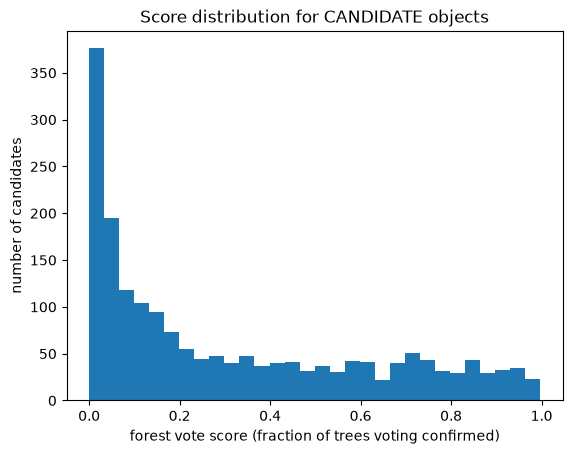

In [62]:
print((cand.forest_vote_score >= 0.9).sum(), 'of', len(cand), 'candidates score >= 0.9')
print((cand.forest_vote_score >= 0.5).sum(), 'of', len(cand), 'candidates score >= 0.5')

top.to_csv('ranked_candidates.csv', index=False)  # for your repo

plt.hist(cand.forest_vote_score, bins=30)
plt.xlabel('forest vote score (fraction of trees voting confirmed)')
plt.ylabel('number of candidates')
plt.title('Score distribution for CANDIDATE objects')
plt.savefig('figures/candidate_scores.png', dpi=150, bbox_inches='tight')
plt.show()

**Score distribution for candidates.** Of 1,873 scored candidates, 91 (4.9%) have a forest vote score of at least 0.9 and 530 (28.3%) at least 0.5. There is a large spike near 0, but the remaining scores are spread broadly between about 0.2 and 1.0 instead of piling up near 1, so many candidates are ambiguous to the model. Candidates are the objects the Kepler vetting process could not resolve, so performance on them is likely lower than the labeled test-set results.

## Do the scores mean what they look like?

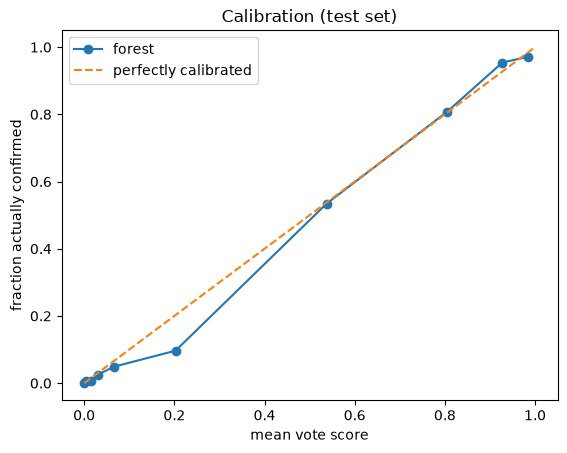

threshold 0.3: precision 0.803, recall 0.952
threshold 0.4: precision 0.842, recall 0.936
threshold 0.5: precision 0.876, recall 0.918
threshold 0.6: precision 0.891, recall 0.876
threshold 0.7: precision 0.909, recall 0.797


In [63]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_score, recall_score

p_test = rf.predict_proba(X_test)[:, 1]

# does a score near 0.9 really mean ~90% confirmed?
frac_pos, mean_score = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
plt.plot(mean_score, frac_pos, marker='o', label='forest')
plt.plot([0, 1], [0, 1], '--', label='perfectly calibrated')
plt.xlabel('mean vote score'); plt.ylabel('fraction actually confirmed')
plt.legend(); plt.title('Calibration (test set)'); 
plt.savefig('figures/calibration.png', dpi=150, bbox_inches='tight'); 
plt.show()

# precision/recall at different thresholds
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_test >= t).astype(int)
    print(f'threshold {t}: precision {precision_score(y_test, pred):.3f}, '
          f'recall {recall_score(y_test, pred):.3f}')

**Calibration.** On the labeled test set, the forest's vote scores track the true fraction of confirmed planets closely: objects scoring around 0.5 were confirmed about half the time and objects around 0.8 about 80% of the time, with a modest over-prediction near a score of 0.2. This was measured on labeled objects only, so it may not carry over to the harder candidate population.

**Threshold trade-off.** Because I weigh missed planets more heavily than false alarms, I examined the decision threshold. Lowering it from 0.5 to 0.3 raises recall for confirmed planets from 0.92 to 0.95 but lowers precision from 0.88 to 0.80. Working back from the rounded precision and recall values, that recovers roughly 17 more planets at a cost of roughly 50 more false alarms, about three false alarms per additional planet. The right threshold depends on how costly follow-up is relative to a missed discovery, so I report the trade-off instead of a single tuned value. The thresholds were compared on the test set, so these numbers illustrate the trade-off and are not a tuned estimate.

**Limitations.** This is a ranking from a simple model, not a discovery. Candidates are the objects vetting could not resolve, so the model is likely less reliable on them than on the labeled test set (the score histogram above is broadly spread, unlike the confident test-set results). Scores are roughly calibrated on labeled objects only. 104 candidates with missing measurements were excluded from the ranking. The main results come from one star-grouped split; five-fold grouped cross-validation gave a similar mean F1 (0.888 for the forest).

## Environment
Package versions used to produce these results (copy into `requirements.txt`):

In [64]:
import sys, sklearn, pandas, numpy, matplotlib
print('python', sys.version.split()[0])
print('scikit-learn==' + sklearn.__version__)
print('pandas==' + pandas.__version__)
print('numpy==' + numpy.__version__)
print('matplotlib==' + matplotlib.__version__)

python 3.14.6
scikit-learn==1.9.1
pandas==3.0.6
numpy==2.5.4
matplotlib==3.11.2
